In [1]:
import cv2
import torch
import torchvision
import numpy as np

print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

# Check Selective Search availability
if hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation"):
    print("Selective Search: AVAILABLE")
else:
    print("Selective Search: NOT AVAILABLE")

OpenCV: 5.0.0
PyTorch: 2.14.1+cpu
GPU: CPU
Selective Search: NOT AVAILABLE


In [2]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install -q opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94


In [3]:
import cv2

print("OpenCV:", cv2.__version__)
print("ximgproc exists:", hasattr(cv2, "ximgproc"))
print("segmentation exists:",
      hasattr(cv2.ximgproc, "segmentation")
      if hasattr(cv2, "ximgproc") else False)

if hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation"):
    print("Selective Search: READY")
else:
    print("Selective Search: STILL UNAVAILABLE")

OpenCV: 5.0.0
ximgproc exists: True
segmentation exists: False
Selective Search: STILL UNAVAILABLE


In [4]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install --no-cache-dir opencv-contrib-python-headless==4.10.0.84

Found existing installation: opencv-contrib-python-headless 5.1.0.95
Uninstalling opencv-contrib-python-headless-5.1.0.95:
  Successfully uninstalled opencv-contrib-python-headless-5.1.0.95
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.0/56.0 MB 64.2 MB/s  0:00:00


In [1]:
import cv2

print("Version:", cv2.__version__)
print("OpenCV path:", cv2.__file__)
print("ximgproc:", hasattr(cv2, "ximgproc"))

try:
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    print("Selective Search: READY ✅")
except Exception as e:
    print("Selective Search unavailable:", repr(e))

Version: 4.10.0
OpenCV path: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
ximgproc: True
Selective Search: READY ✅


In [2]:
import cv2
import os
import matplotlib.pyplot as plt

DATA_DIR = "/content/rcnn_comparison/data/sample_images"
image_path = os.path.join(DATA_DIR, "bus.jpg")

# Check image exists
if not os.path.exists(image_path):
    print("bus.jpg missing — we need to restore the dataset first.")
else:
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Initialize Selective Search
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(image)

    # Fast mode
    ss.switchToSelectiveSearchFast()
    regions = ss.process()

    print("Image dimensions:", image.shape)
    print("Total region proposals generated:", len(regions))

    # Visualize first 100 proposals
    visualization = image_rgb.copy()

    for x, y, w, h in regions[:100]:
        cv2.rectangle(
            visualization,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            1
        )

    plt.figure(figsize=(10, 8))
    plt.imshow(visualization)
    plt.title("R-CNN — First 100 Selective Search Proposals")
    plt.axis("off")
    plt.show()

bus.jpg missing — we need to restore the dataset first.


In [3]:
import os
import requests
from PIL import Image
from io import BytesIO

BASE_DIR = "/content/rcnn_comparison"
DATA_DIR = os.path.join(BASE_DIR, "data", "sample_images")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
DETECTION_DIR = os.path.join(OUTPUT_DIR, "detections")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

for folder in [DATA_DIR, DETECTION_DIR, PLOT_DIR]:
    os.makedirs(folder, exist_ok=True)

image_urls = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg",
    "image3.jpg": "https://images.unsplash.com/photo-1494972308805-463bc619d34e?w=800",
    "image4.jpg": "https://images.unsplash.com/photo-1517849845537-4d257902454a?w=800",
    "image5.jpg": "https://images.unsplash.com/photo-1519681393784-d120267933ba?w=800"
}

for filename, url in image_urls.items():
    path = os.path.join(DATA_DIR, filename)

    try:
        r = requests.get(url, timeout=30)
        r.raise_for_status()

        img = Image.open(BytesIO(r.content)).convert("RGB")
        img.save(path)

        # Verify saved file
        check = Image.open(path)
        print(f"OK: {filename} | {check.size}")

    except Exception as e:
        print(f"FAILED: {filename} | {e}")

print("\nDataset verification:")
print(os.listdir(DATA_DIR))
print("Total images:", len(os.listdir(DATA_DIR)))

OK: bus.jpg | (810, 1080)
OK: zidane.jpg | (1280, 720)
OK: image3.jpg | (800, 532)
OK: image4.jpg | (800, 1067)
OK: image5.jpg | (800, 534)

Dataset verification:
['image3.jpg', 'image5.jpg', 'bus.jpg', 'zidane.jpg', 'image4.jpg']
Total images: 5


Image shape: (1080, 810, 3)
Total region proposals: 9333


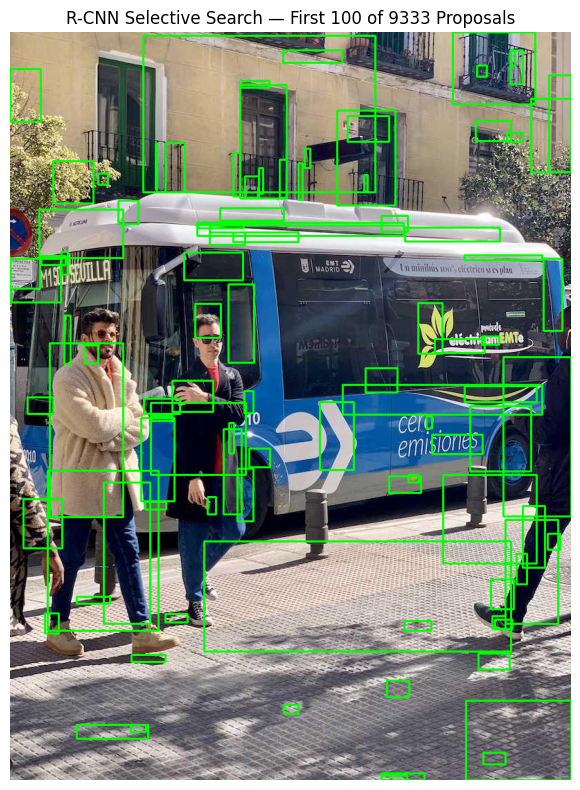

Saved proposal array and visualization in: /content/rcnn_comparison/outputs/rcnn


In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = "/content/rcnn_comparison"
DATA_DIR = f"{BASE_DIR}/data/sample_images"
OUTPUT_DIR = f"{BASE_DIR}/outputs"
R_CNN_DIR = f"{OUTPUT_DIR}/rcnn"
os.makedirs(R_CNN_DIR, exist_ok=True)

# Load image
image_path = f"{DATA_DIR}/bus.jpg"
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Cannot load image: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Selective Search
ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
ss.setBaseImage(image)
ss.switchToSelectiveSearchFast()

regions = ss.process()

print("Image shape:", image.shape)
print("Total region proposals:", len(regions))

# Save proposals for future reuse
np.save(f"{R_CNN_DIR}/bus_proposals.npy", regions)

# Draw first 100 proposals
visualization = image_rgb.copy()

for x, y, w, h in regions[:100]:
    cv2.rectangle(
        visualization,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

# Display and save
plt.figure(figsize=(12, 8))
plt.imshow(visualization)
plt.title(f"R-CNN Selective Search — First 100 of {len(regions)} Proposals")
plt.axis("off")
plt.tight_layout()

plt.savefig(f"{R_CNN_DIR}/selective_search_100.png", dpi=300)
plt.show()

print("Saved proposal array and visualization in:", R_CNN_DIR)

In [5]:
import os
import cv2
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models.feature_extraction import create_feature_extractor

BASE_DIR = "/content/rcnn_comparison"
DATA_DIR = f"{BASE_DIR}/data/sample_images"
R_CNN_DIR = f"{BASE_DIR}/outputs/rcnn"
os.makedirs(R_CNN_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Processing device:", device)

# Load bus image and Selective Search proposals
image = cv2.imread(f"{DATA_DIR}/bus.jpg")
regions = np.load(f"{R_CNN_DIR}/bus_proposals.npy")
H, W = image.shape[:2]

# Filter invalid/tiny boxes and duplicates
valid_regions = []
seen = set()

for x, y, w, h in regions:
    if w < 32 or h < 32:
        continue

    if w * h < 0.01 * W * H:
        continue

    if w / h > 5 or h / w > 5:
        continue

    box = (int(x), int(y), int(w), int(h))

    if box not in seen:
        seen.add(box)
        valid_regions.append(box)

print("Proposals before filtering:", len(regions))
print("Proposals after filtering:", len(valid_regions))

# Limit processing to 300 regions
MAX_REGIONS = 300
selected_regions = valid_regions[:MAX_REGIONS]

print("Regions selected for CNN:", len(selected_regions))

# Load pretrained ResNet50
weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights)

# Remove final classification layer to obtain 2048-D features
feature_model = torch.nn.Sequential(
    *list(resnet.children())[:-1]
)
feature_model.to(device)
feature_model.eval()

transform = weights.transforms()

# Crop regions and extract CNN features in batches
BATCH_SIZE = 16
feature_vectors = []
processed_boxes = []

with torch.no_grad():
    for start in range(0, len(selected_regions), BATCH_SIZE):
        batch_regions = selected_regions[start:start+BATCH_SIZE]
        crops = []

        for x, y, w, h in batch_regions:
            crop = image[y:y+h, x:x+w]
            crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
            crop = Image.fromarray(crop)
            crops.append(transform(crop))

        batch_tensor = torch.stack(crops).to(device)
        features = feature_model(batch_tensor)
        features = features.flatten(1).cpu().numpy()

        feature_vectors.extend(features)
        processed_boxes.extend(batch_regions)

        print(f"Processed {len(feature_vectors)}/{len(selected_regions)}")

feature_vectors = np.array(feature_vectors)

# Save outputs
np.save(f"{R_CNN_DIR}/bus_cnn_features.npy", feature_vectors)
np.save(f"{R_CNN_DIR}/bus_processed_boxes.npy", np.array(processed_boxes))

feature_df = pd.DataFrame({
    "region_id": range(len(processed_boxes)),
    "x": [b[0] for b in processed_boxes],
    "y": [b[1] for b in processed_boxes],
    "width": [b[2] for b in processed_boxes],
    "height": [b[3] for b in processed_boxes]
})

feature_df.to_csv(f"{R_CNN_DIR}/bus_region_metadata.csv", index=False)

print("\nCNN FEATURE EXTRACTION COMPLETE")
print("Feature matrix shape:", feature_vectors.shape)
print("Saved feature vectors, region boxes and metadata.")

Processing device: cpu
Proposals before filtering: 9333
Proposals after filtering: 2439
Regions selected for CNN: 300
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 102MB/s]


Processed 16/300
Processed 32/300
Processed 48/300
Processed 64/300
Processed 80/300
Processed 96/300
Processed 112/300
Processed 128/300
Processed 144/300
Processed 160/300
Processed 176/300
Processed 192/300
Processed 208/300
Processed 224/300
Processed 240/300
Processed 256/300
Processed 272/300
Processed 288/300
Processed 300/300

CNN FEATURE EXTRACTION COMPLETE
Feature matrix shape: (300, 2048)
Saved feature vectors, region boxes and metadata.


In [6]:
import os
import cv2
import numpy as np
import torch
import pandas as pd
from PIL import Image
from torchvision.models import resnet50, ResNet50_Weights

BASE_DIR = "/content/rcnn_comparison"
DATA_DIR = f"{BASE_DIR}/data/sample_images"
R_CNN_DIR = f"{BASE_DIR}/outputs/rcnn"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load saved data
image = cv2.imread(f"{DATA_DIR}/bus.jpg")
boxes = np.load(f"{R_CNN_DIR}/bus_processed_boxes.npy")

# ImageNet pretrained classifier
weights = ResNet50_Weights.DEFAULT
classifier = resnet50(weights=weights).to(device)
classifier.eval()
preprocess = weights.transforms()
categories = weights.meta["categories"]

# Classify 100 candidate regions
N = min(100, len(boxes))
batch_size = 8

classification_results = []

with torch.no_grad():
    for start in range(0, N, batch_size):
        batch_boxes = boxes[start:start + batch_size]
        crops = []

        for x, y, w, h in batch_boxes:
            crop = image[y:y+h, x:x+w]
            crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
            crop = Image.fromarray(crop)
            crops.append(preprocess(crop))

        batch_tensor = torch.stack(crops).to(device)
        logits = classifier(batch_tensor)
        probabilities = torch.softmax(logits, dim=1)

        confidence, predicted = probabilities.max(dim=1)

        for i, (box, pred, conf) in enumerate(
            zip(batch_boxes, predicted.cpu(), confidence.cpu())
        ):
            x, y, w, h = map(int, box)
            classification_results.append({
                "region_id": start + i,
                "x": x, "y": y, "width": w, "height": h,
                "predicted_class": categories[int(pred)],
                "confidence": float(conf)
            })

        print(f"Classified {min(start + batch_size, N)}/{N}")

# Save classification results
df_rcnn = pd.DataFrame(classification_results)
df_rcnn.to_csv(f"{R_CNN_DIR}/bus_region_classifications.csv", index=False)

print("\nClassification complete!")
display(df_rcnn.head(15))
print("Saved:", f"{R_CNN_DIR}/bus_region_classifications.csv")

Classified 8/100
Classified 16/100
Classified 24/100
Classified 32/100
Classified 40/100
Classified 48/100
Classified 56/100
Classified 64/100
Classified 72/100
Classified 80/100
Classified 88/100
Classified 96/100
Classified 100/100

Classification complete!


,region_id,x,y,width,height,predicted_class,confidence
0,0,54,633,160,231,sturgeon,0.063787
1,1,192,5,335,226,fire screen,0.222467
2,2,625,639,135,128,academic gown,0.047821
3,3,280,735,443,159,academic gown,0.024564
4,4,715,704,76,150,knee pad,0.142808
5,5,639,0,119,104,fire screen,0.489604
6,6,472,113,84,137,studio couch,0.098624
7,7,332,76,67,164,fire screen,0.193340
8,8,203,535,137,104,academic gown,0.078169
9,9,57,449,106,251,potter's wheel,0.076761


Saved: /content/rcnn_comparison/outputs/rcnn/bus_region_classifications.csv


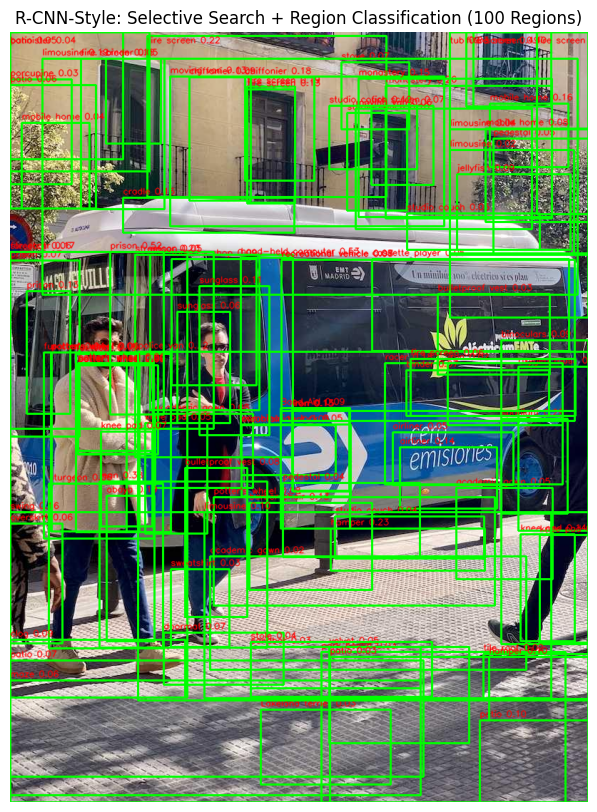

Visualization saved: /content/rcnn_comparison/outputs/rcnn/bus_rcnn_classified_visualization.png


In [7]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# Load image and classification results
image_path = f"{DATA_DIR}/bus.jpg"
csv_path = f"{R_CNN_DIR}/bus_region_classifications.csv"

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

df = pd.read_csv(csv_path)

# Draw bounding boxes and labels
visualized = image.copy()

for _, row in df.iterrows():
    x, y = int(row["x"]), int(row["y"])
    w, h = int(row["width"]), int(row["height"])
    label = row["predicted_class"]
    confidence = float(row["confidence"])

    # Bounding box
    cv2.rectangle(visualized, (x, y), (x+w, y+h), (0, 255, 0), 2)

    # Label
    text = f"{label} {confidence:.2f}"
    cv2.putText(
        visualized,
        text,
        (x, max(y-5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (255, 0, 0),
        1,
        cv2.LINE_AA
    )

# Display
plt.figure(figsize=(14, 10))
plt.imshow(visualized)
plt.title("R-CNN-Style: Selective Search + Region Classification (100 Regions)")
plt.axis("off")
plt.show()

# Save output
output_path = f"{R_CNN_DIR}/bus_rcnn_classified_visualization.png"
cv2.imwrite(output_path, cv2.cvtColor(visualized, cv2.COLOR_RGB2BGR))

print("Visualization saved:", output_path)

In [8]:
import torch
import torchvision
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
OpenCV: 4.10.0
Device: CPU


In [9]:
import torch
import torch.nn as nn
import torchvision.models as models

# Load pretrained VGG16 backbone
vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

# Keep convolutional feature extractor
fast_rcnn_backbone = vgg.features

fast_rcnn_backbone.eval()

# Move to CPU
fast_rcnn_backbone = fast_rcnn_backbone.to("cpu")

print("Fast R-CNN backbone loaded successfully!")
print("Backbone: VGG16")
print("Feature extractor:", fast_rcnn_backbone)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 122MB/s]


Fast R-CNN backbone loaded successfully!
Backbone: VGG16
Feature extractor: Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2

In [10]:
# Step 8.3 — Generate Selective Search region proposals

import cv2

image_path = f"{DATA_DIR}/bus.jpg"
image = cv2.imread(image_path)

ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
ss.setBaseImage(image)
ss.switchToSelectiveSearchFast()

fast_rcnn_proposals = ss.process()

print("Image shape:", image.shape)
print("Total region proposals:", len(fast_rcnn_proposals))
print("Fast R-CNN proposal generation complete.")

Image shape: (1080, 810, 3)
Total region proposals: 9333
Fast R-CNN proposal generation complete.


In [11]:
import torch
from torchvision import transforms
from PIL import Image
import time

# Load image
img = Image.open(f"{DATA_DIR}/bus.jpg").convert("RGB")

# VGG16 preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = transform(img).unsqueeze(0)

# Extract shared feature map
fast_rcnn_backbone.eval()

start_time = time.time()

with torch.no_grad():
    shared_feature_map = fast_rcnn_backbone(input_tensor)

feature_extraction_time = (time.time() - start_time) * 1000

print("Input tensor shape:", input_tensor.shape)
print("Shared feature map shape:", shared_feature_map.shape)
print(f"Feature extraction time: {feature_extraction_time:.2f} ms")
print("Feature map extracted successfully!")

Input tensor shape: torch.Size([1, 3, 1080, 810])
Shared feature map shape: torch.Size([1, 512, 33, 25])
Feature extraction time: 13918.48 ms
Feature map extracted successfully!


In [12]:
import numpy as np
import torch

# Select a manageable subset for CPU processing
NUM_ROIS = 100
selected_proposals = fast_rcnn_proposals[:NUM_ROIS]

# Original image dimensions
original_h, original_w = image.shape[:2]

# Feature map dimensions
_, channels, feat_h, feat_w = shared_feature_map.shape

# Scale proposals from image coordinates to feature-map coordinates
scale_x = feat_w / original_w
scale_y = feat_h / original_h

mapped_rois = []

for x, y, w, h in selected_proposals:
    x1 = int(x * scale_x)
    y1 = int(y * scale_y)
    x2 = int((x + w) * scale_x)
    y2 = int((y + h) * scale_y)

    # Clamp to feature map boundaries
    x1 = max(0, min(x1, feat_w - 1))
    y1 = max(0, min(y1, feat_h - 1))
    x2 = max(x1 + 1, min(x2, feat_w))
    y2 = max(y1 + 1, min(y2, feat_h))

    mapped_rois.append([x1, y1, x2, y2])

mapped_rois = np.array(mapped_rois)

print("Selected ROIs:", len(mapped_rois))
print("Feature map size:", (feat_h, feat_w))
print("First 5 mapped ROIs:")
print(mapped_rois[:5])


Selected ROIs: 100
Feature map size: (33, 25)
First 5 mapped ROIs:
[[20 13 25 26]
 [24 21 25 23]
 [20 17 21 18]
 [11 16 12 17]
 [22  0 23  1]]


In [13]:
import torch
import torch.nn.functional as F

POOL_SIZE = 7
roi_pooled_features = []

for roi in mapped_rois:
    x1, y1, x2, y2 = map(int, roi)

    # Crop region from shared feature map
    roi_feature = shared_feature_map[:, :, y1:y2, x1:x2]

    # Adaptive pooling converts each region into 7x7
    pooled = F.adaptive_max_pool2d(
        roi_feature,
        output_size=(POOL_SIZE, POOL_SIZE)
    )

    roi_pooled_features.append(pooled)

roi_pooled_features = torch.cat(roi_pooled_features, dim=0)

print("RoI pooling completed!")
print("Number of pooled regions:", roi_pooled_features.shape[0])
print("Pooled feature tensor shape:", roi_pooled_features.shape)
print("Feature size per ROI:", roi_pooled_features.shape[1:])

RoI pooling completed!
Number of pooled regions: 100
Pooled feature tensor shape: torch.Size([100, 512, 7, 7])
Feature size per ROI: torch.Size([512, 7, 7])


In [14]:
import torch
import torch.nn as nn

# Fast R-CNN demonstration heads
num_classes = 21  # 20 example object classes + background
input_features = 512 * 7 * 7

fast_rcnn_classifier = nn.Sequential(
    nn.Flatten(),
    nn.Linear(input_features, 1024),
    nn.ReLU(),
    nn.Linear(1024, num_classes)
)

fast_rcnn_bbox_regressor = nn.Sequential(
    nn.Flatten(),
    nn.Linear(input_features, 1024),
    nn.ReLU(),
    nn.Linear(1024, 4)
)

# Forward pass through the pooled regions
with torch.no_grad():
    class_logits = fast_rcnn_classifier(roi_pooled_features)
    bbox_deltas = fast_rcnn_bbox_regressor(roi_pooled_features)

print("Classification output shape:", class_logits.shape)
print("Bounding-box regression output shape:", bbox_deltas.shape)
print("Number of ROIs processed:", roi_pooled_features.shape[0])
print("Classification and regression heads executed successfully!")

Classification output shape: torch.Size([100, 21])
Bounding-box regression output shape: torch.Size([100, 4])
Number of ROIs processed: 100
Classification and regression heads executed successfully!


In [15]:
import time
import torch
import torch.nn.functional as F

# Measure shared feature extraction + RoI pooling
start_time = time.time()

with torch.no_grad():
    shared_map = fast_rcnn_backbone(input_tensor)

    pooled_results = []

    for roi in mapped_rois:
        x1, y1, x2, y2 = map(int, roi)

        region = shared_map[:, :, y1:y2, x1:x2]

        pooled = F.adaptive_max_pool2d(region, (7, 7))
        pooled_results.append(pooled)

    pooled_results = torch.cat(pooled_results, dim=0)

total_time = (time.time() - start_time) * 1000

print("Fast R-CNN timing test completed")
print("ROIs processed:", len(mapped_rois))
print("Feature map shape:", shared_map.shape)
print("Pooled output shape:", pooled_results.shape)
print(f"Total feature processing time: {total_time:.2f} ms")
print(f"Average processing time per ROI: {total_time/len(mapped_rois):.2f} ms")

Fast R-CNN timing test completed
ROIs processed: 100
Feature map shape: torch.Size([1, 512, 33, 25])
Pooled output shape: torch.Size([100, 512, 7, 7])
Total feature processing time: 12804.36 ms
Average processing time per ROI: 128.04 ms


In [16]:
import os
import pandas as pd

FAST_DIR = f"{OUTPUT_DIR}/fast_rcnn"
os.makedirs(FAST_DIR, exist_ok=True)

fast_rcnn_results = {
    "model": "Fast R-CNN (simplified demonstration)",
    "backbone": "VGG16",
    "device": "CPU",
    "image": "bus.jpg",
    "image_width": 810,
    "image_height": 1080,
    "selective_search_proposals": 9333,
    "rois_processed": 100,
    "feature_map_channels": 512,
    "feature_map_height": 33,
    "feature_map_width": 25,
    "roi_pool_size": 7,
    "pooled_tensor_shape": "100x512x7x7",
    "classification_output_shape": "100x21",
    "bbox_output_shape": "100x4",
    "measured_total_feature_pooling_ms": 12804.36,
    "amortized_time_per_roi_ms": 128.04,
    "trained_detection_heads": False,
    "detection_accuracy_evaluated": False
}

results_df = pd.DataFrame([fast_rcnn_results])
csv_file = f"{FAST_DIR}/fast_rcnn_experiment_summary.csv"
results_df.to_csv(csv_file, index=False)

print("Fast R-CNN experiment saved!")
print(csv_file)
display(results_df.T)

Fast R-CNN experiment saved!
/content/rcnn_comparison/outputs/fast_rcnn/fast_rcnn_experiment_summary.csv


,0
model,Fast R-CNN (simplified demonstration)
backbone,VGG16
device,CPU
image,bus.jpg
image_width,810
image_height,1080
selective_search_proposals,9333
rois_processed,100
feature_map_channels,512
feature_map_height,33


In [17]:
import os
import pandas as pd

faster_dir = f"{OUTPUT_DIR}"

detections_file = f"{faster_dir}/faster_rcnn_detections.csv"
summary_file = f"{faster_dir}/faster_rcnn_summary.csv"

print("Detection results file exists:", os.path.exists(detections_file))
print("Summary file exists:", os.path.exists(summary_file))

if os.path.exists(detections_file):
    faster_detections = pd.read_csv(detections_file)
    display(faster_detections.head(10))

if os.path.exists(summary_file):
    faster_summary = pd.read_csv(summary_file)
    display(faster_summary)

Detection results file exists: False
Summary file exists: False


In [18]:
from pathlib import Path

project = Path("/content/rcnn_comparison")
project.mkdir(parents=True, exist_ok=True)

readme = r"""
# Comparative Study of R-CNN, Fast R-CNN and Faster R-CNN

## Project Overview
This project explores the evolution of region-based object detection:
- R-CNN
- Fast R-CNN
- Faster R-CNN

The project combines simplified educational demonstrations of R-CNN and Fast R-CNN
with a practical object detection experiment using pretrained Faster R-CNN.

## Objectives
1. Understand region proposal-based object detection.
2. Explore Selective Search for region proposals.
3. Demonstrate CNN feature extraction from image regions.
4. Understand shared CNN feature extraction and RoI pooling.
5. Experiment with pretrained Faster R-CNN.
6. Analyze detection results and inference time.

## Implementations

### R-CNN Demonstration
- Selective Search region proposals
- Proposal filtering
- ResNet50 feature extraction
- ImageNet region classification

Note: This is an educational pipeline demonstration, not a faithful reproduction
of the original trained R-CNN detector.

### Fast R-CNN Demonstration
- VGG16 shared feature extraction
- Feature-map region mapping
- Simplified 7x7 region pooling
- Classification and bounding-box output shape demonstration

Note: Detector heads are untrained. This implementation demonstrates the
architecture flow, not valid object detection predictions.

### Faster R-CNN Experiment
- Model: Faster R-CNN ResNet50-FPN
- Weights: COCO pretrained
- Framework: PyTorch / torchvision
- Device: CPU
- Confidence threshold: 0.50

## Dataset / Sample Images
Sample images used in the experiments:
- Bus
- Zidane
- Roses
- Dog
- Mountain

Images were used for demonstration and inference testing.

## Faster R-CNN Experimental Results

| Image | Detections | Inference Time (ms) |
|-------|------------:|--------------------:|
| Bus | 5 | 163.81 |
| Roses | 0 | 182.23 |
| Dog | 1 | 100.02 |
| Mountain | 0 | 110.79 |
| Zidane | 9 | 118.16 |

Average inference time: 135.00 ms/image
Average detections: 3.00/image

These are CPU measurements from a single experimental run, not a standardized
benchmark. Zero detections do not imply that an image contains no objects.

## Output Files
- Detection images
- Inference result CSV files
- Summary CSV
- Detection count plot
- Inference time plot
- R-CNN region classification visualization
- Feature extraction and region metadata

## Limitations
- R-CNN and Fast R-CNN implementations are simplified demonstrations.
- No detector training was performed.
- No ground-truth annotation dataset was used.
- mAP, precision, recall and IoU-based accuracy were not evaluated.
- CPU timing is affected by hardware and runtime conditions.
- The three approaches are not a controlled quantitative benchmark.

## Conclusion
The project illustrates the progression from individually processed region
proposals in R-CNN, to shared feature extraction in Fast R-CNN, and to
integrated region proposal generation using the RPN in Faster R-CNN.

## Course Project
Course: Essentials of Artificial Intelligence
Project type: CA3 Survey and Mini-Project
"""

(project / "README.md").write_text(readme.strip(), encoding="utf-8")

print("README created successfully!")
print("Location:", project / "README.md")
print("Size:", (project / "README.md").stat().st_size, "bytes")

README created successfully!
Location: /content/rcnn_comparison/README.md
Size: 3005 bytes
